# Search-09-LinearProgramming : Programmation Lineaire et Simplexe

**Navigation** : [<< DancingLinks](Search-08-DancingLinks.ipynb) | [Index](../README.md) | [LP → convexe >>](Search-09f-ConvexOptimisation-Python.ipynb) · [SymbolicAutomata >>](Search-10-SymbolicAutomata.ipynb)

## La Programmation Lineaire (PL)

Ce notebook présente la **programmation lineaire** (Linear Programming, LP), une technique d'optimisation fondamentale pour résoudre des problèmes de decision sous contraintes. Nous utiliserons **PuLP**, une librairie Python intuitive pour modeliser et résoudre des problèmes lineaires et entiers.

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Comprendre** la formulation mathématique d'un problème lineaire (forme standard, forme canonique)
2. **Formuler** des problèmes réels en modèles de programmation lineaire (variables, objectif, contraintes)
3. **Resoudre** des problèmes PL et PLNE avec PuLP (solver CBC)
4. **Analyser** les résultats et l'analyse de sensibilite (valeurs duales, shadow prices)

### Prerequis
- Python basique (listes, dictionnaires, boucles)
- Notions d'algebre lineaire (vecteurs, matrices, systèmes lineaires)
- Concepts d'optimisation (fonction objectif, contraintes, optimum)

### Duree estimee : 2 heures

***

## References

- **PuLP documentation** : https://coin-or.github.io/pulp/
- **Solver** : CBC (Coin-OR Branch and Cut), inclus par defaut
- **Théorie** : Algorithme du simplexe, theoreme de dualite
- **Notebook connexe** : [App-10-Portfolio](../Part3-Cas-pratiques/App-10-Portfolio.ipynb)

In [1]:
# Imports
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from typing import List, Tuple, Dict, Optional

%matplotlib inline

print("Environnement pret pour la Programmation Lineaire.")
print(f"Python {sys.version}")

Environnement pret pour la Programmation Lineaire.
Python 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


## 1. Introduction a la Programmation Lineaire (~15 min)

### 1.1 Definition et motivation

La **programmation lineaire** (PL ou Linear Programming, LP) est une méthode d'optimisation qui permet de déterminer la meilleure solution (optimale) a un problème donne, représente par des fonctions lineaires.

**Applications classiques** :
- **Production** : maximiser le profit sous contraintes de ressources
- **Transport** : minimiser les couts d'acheminement
- **Finance** : allocation de portefeuille, optimisation de rendement
- **Logistique** : planification de routes, gestion de stocks
- **Scheduling** : ordonnancement de tâches

### 1.2 Forme standard d'un problème lineaire

Un problème de programmation lineaire s'ecrit sous la forme suivante :

$$\begin{align}
\max \quad & z = c^T x = \sum_{j=1}^n c_j x_j \\
\text{s.c.} \quad & \sum_{j=1}^n a_{ij} x_j \leq b_i, \quad i = 1, ..., m \\
& x_j \geq 0, \quad j = 1, ..., n
\end{align}$$

**Composants** :
- **Fonction objectif** $z = c^T x$ : fonction lineaire a optimiser (maximiser ou minimiser)
- **Contraintes** $Ax \leq b$ : $m$ contraintes lineaires
- **Variables de decision** $x$ : $n$ variables non négatives

### 1.3 Formes de problèmes PL

Les problèmes de programmation lineaire peuvent se présenter sous différentes formes :

**Forme canonique (maximisation)** :
$$\begin{align}
\max \quad & c^T x \\
\text{s.c.} \quad & Ax \leq b \\
& x \geq 0
\end{align}$$

**Forme standard (egalites)** :
$$\begin{align}
\max \quad & c^T x \\
\text{s.c.} \quad & Ax = b \\
& x \geq 0
\end{align}$$

**Transformation entre formes** :
- $Ax \leq b \implies Ax + s = b, \quad s \geq 0$ (variable d'ecart)
- $Ax \geq b \implies Ax - s = b, \quad s \geq 0$ (variable de surplus)
- $\min c^T x \iff \max -c^T x$
- Variable libre $x \in \mathbb{R} \implies x = x^+ - x^-, \quad x^+, x^- \geq 0$

### 1.4 Interpretation geometrique

Geometriquement, un problème PL peut etre représente comme suit :
- Chaque contrainte définit un demi-espace
- L'intersection des demi-espaces forme un **polyedre** (region admissible)
- La solution optimale se trouve toujours en un **sommet** du polyedre

> **Theoreme fondamental** : Si un problème PL admet une solution optimale, alors il existe une solution optimale correspondant a un sommet extrême de la region admissible.

### 1.5 Algorithme du simplexe

L'**algorithme du simplexe**, développé par George Dantzig en 1947, est la méthode classique pour résoudre les problèmes de programmation lineaire.

**Principe** :
1. Commencer a un sommet initial de la region admissible
2. Deplacer vers un sommet adjacent qui amélioré l'objectif
3. Repeter jusqu'a ce qu'aucune amélioration ne soit possible
4. Le sommet final est optimal

**Complexite** :
- Pire cas : exponentielle (rare en pratique)
- Cas moyen : polynomiale (très efficace en pratique)
- Méthodes de point interieur : polynomiales garantie

### 1.6 Exemple introductif - Problème de production

Une entreprise fabrique deux produits **P1** et **P2** :
- P1 rapporte 3€ par unite, P2 rapporte 2€ par unite
- P1 necessite 1h de machine, P2 necessite 2h de machine (max 4h disponibles)
- P1 necessite 2h de main d'oeuvre, P2 necessite 1h de main d'oeuvre (max 5h disponibles)

**Question** : Combien d'unites de P1 et P2 produire pour maximiser le profit ?

**Formulation** :
- Variables : $x_1$ = quantite de P1, $x_2$ = quantite de P2
- Objectif : $\max z = 3x_1 + 2x_2$ (profit en euros)
- Contraintes :
  - $x_1 + 2x_2 \leq 4$ (heures machine)
  - $2x_1 + x_2 \leq 5$ (heures main d'oeuvre)
  - $x_1, x_2 \geq 0$ (non-negativite)

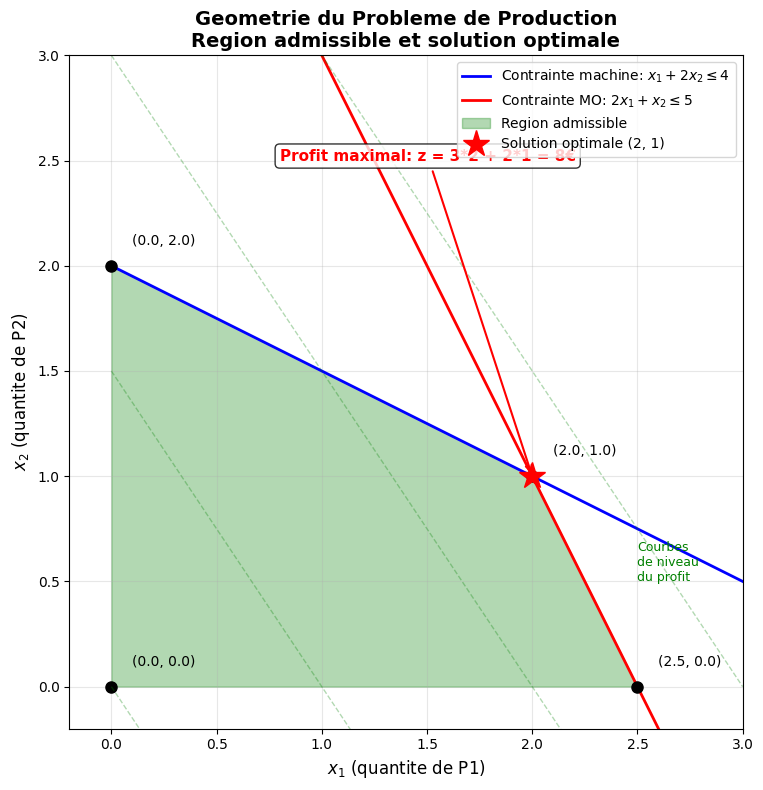

Visualisation geometrique du probleme de production

Sommets de la region admissible (et profit z = 3*x1 + 2*x2) :
  (0, 0)   : Profit = 3*0 + 2*0   = 0
  (0, 2)   : Profit = 3*0 + 2*2   = 4
  (2, 1)   : Profit = 3*2 + 2*1   = 8   <- OPTIMAL
    Machine: 2 + 2*1 = 4 <= 4 (saturee) | MO: 2*2 + 1 = 5 <= 5 (saturee)
  (2.5, 0) : Profit = 3*2.5 + 2*0 = 7.5
    Machine: 2.5 + 2*0 = 2.5 <= 4 | MO: 2*2.5 + 0 = 5 <= 5 (saturee)

Solution optimale : x1=2, x2=1, Profit = 8 (sommet Machine ∩ MO)
(Confirme par le solveur PuLP/CBC cellule suivante.)


In [2]:
# Visualisation geometrique du probleme de production
fig, ax = plt.subplots(figsize=(10, 8))

# Domaine de tracage
x = np.linspace(0, 3, 400)

# Contrainte 1: x1 + 2*x2 <= 4 => x2 <= (4 - x1) / 2
y1 = (4 - x) / 2

# Contrainte 2: 2*x1 + x2 <= 5 => x2 <= 5 - 2*x1
y2 = 5 - 2 * x

# Tracer les contraintes
ax.plot(x, y1, 'b-', linewidth=2, label=r'Contrainte machine: $x_1 + 2x_2 \leq 4$')
ax.plot(x, y2, 'r-', linewidth=2, label=r'Contrainte MO: $2x_1 + x_2 \leq 5$')

# Region admissible (intersection des contraintes)
y_feasible = np.minimum(y1, y2)
ax.fill_between(x, 0, y_feasible, where=(y_feasible >= 0),
                   alpha=0.3, color='green', label='Region admissible')

# Sommets du polyedre (intersections des contraintes + axes) :
#   (0,0)   : origine (axes x1>=0 et x2>=0)
#   (0,2)   : axe x1=0  sur la contrainte machine  (0+2*2=4)
#   (2,1)   : intersection machine ∩ MO  (2+2*1=4 ET 2*2+1=5)  <- OPTIMAL
#   (2.5,0) : axe x2=0  sur la contrainte MO      (2*2.5+0=5)
vertices = [(0, 0), (0, 2), (2, 1), (2.5, 0)]
for vx, vy in vertices:
    ax.plot(vx, vy, 'ko', markersize=8)
    ax.text(vx + 0.1, vy + 0.1, f'({vx:.1f}, {vy:.1f})', fontsize=10)

# Solution optimale (2, 1)
ax.plot(2, 1, 'r*', markersize=20, label='Solution optimale (2, 1)')

# Courbes de niveau de la fonction objectif
for z_val in [0, 3, 6, 9]:
    y_obj = (z_val - 3 * x) / 2
    ax.plot(x, y_obj, 'g--', alpha=0.3, linewidth=1)
ax.text(2.5, 0.5, 'Courbes\nde niveau\ndu profit', fontsize=9, color='green')

# Annotation de la solution
ax.annotate('Profit maximal: z = 3*2 + 2*1 = 8€',
             xy=(2, 1), xytext=(0.8, 2.5),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
             fontsize=11, color='red', fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Mise en forme
ax.set_xlabel('$x_1$ (quantite de P1)', fontsize=12)
ax.set_ylabel('$x_2$ (quantite de P2)', fontsize=12)
ax.set_title('Geometrie du Probleme de Production\nRegion admissible et solution optimale',
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim(-0.2, 3)
ax.set_ylim(-0.2, 3)
ax.set_aspect('equal')

plt.tight_layout()
plt.show()

print("Visualisation geometrique du probleme de production")
print("\nSommets de la region admissible (et profit z = 3*x1 + 2*x2) :")
print("  (0, 0)   : Profit = 3*0 + 2*0   = 0")
print("  (0, 2)   : Profit = 3*0 + 2*2   = 4")
print("  (2, 1)   : Profit = 3*2 + 2*1   = 8   <- OPTIMAL")
print("    Machine: 2 + 2*1 = 4 <= 4 (saturee) | MO: 2*2 + 1 = 5 <= 5 (saturee)")
print("  (2.5, 0) : Profit = 3*2.5 + 2*0 = 7.5")
print("    Machine: 2.5 + 2*0 = 2.5 <= 4 | MO: 2*2.5 + 0 = 5 <= 5 (saturee)")
print("\nSolution optimale : x1=2, x2=1, Profit = 8 (sommet Machine ∩ MO)")
print("(Confirme par le solveur PuLP/CBC cellule suivante.)")

### Interpretation : Visualisation geometrique

**Composantes de la visualisation** :

| Élément | Signification |
|----------|---------------|
| **Lignes bleues/rouges** | Contraintes (frontieres du domaine admissible) |
| **Region verte** | Region admissible (satisfait toutes les contraintes) |
| **Points noirs** | Sommets du polyedre |
| **Etoile rouge** | Solution optimale |
| **Lignes vertes** | Courbes de niveau de la fonction objectif |

**Points cles** :
1. La region admissible est un polygone convexe (intersection de demi-espaces)
2. La solution optimale se trouve au sommet (2, 1) — intersection des contraintes Machine et MO, qui sont toutes deux saturées
3. Le profit maximal est de 8 euros
4. Il faut produire 2 unites de P1 et 1 unite de P2

> **Propriete importante** : Pour un problème de maximisation, la courbe de niveau du profit "pousse" vers le haut. La solution optimale est le dernier point de contact avant de sortir de la region admissible.

> **Theoreme** : Si la region admissible est bornee et non vide, il existe toujours une solution optimale correspondant a un sommet extrême.

## 2. Installation et Premier Exemple avec PuLP (~15 min)

### 2.1 Installation de PuLP

**PuLP** est une librairie Python open-source pour la programmation lineaire. Elle permet de :
- Decrire des problèmes PL de manière intuitive
- Utiliser différents solveurs (CBC, GLPK, CPLEX, Gurobi)
- Analyser les résultats (valeur optimale, variables, sensibilite)

**Solver CBC** (Coin-OR Branch and Cut) est inclus par defaut et ne necessite pas d'installation supplementaire.

In [3]:
# PuLP (pulp >= 2.8.0) : solveur de programmation lineaire (CBC, HiGHS).
# Dependence declaree dans requirements.txt ; import et verification en cellule suivante.

import sys
print(f"Python {sys.version}")
print("\nPuLP pret a etre importe (voir cellule suivante).")

Python 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]

PuLP pret a etre importe (voir cellule suivante).


Import de PuLP et vérification

In [4]:
# Import de PuLP et verification
import pulp

print("=== PuLP - Programmation Lineaire en Python ===\n")
print(f"Version PuLP : {pulp.__version__}")
print(f"Solveur disponible par defaut : CBC (Coin-OR Branch and Cut)")
print("\nPuLP est pret !")

=== PuLP - Programmation Lineaire en Python ===

Version PuLP : 3.3.0
Solveur disponible par defaut : CBC (Coin-OR Branch and Cut)

PuLP est pret !


### 2.2 Structure d'un problème PuLP

Un problème PuLP se compose de :

1. **Creation du problème** : `LpProblem(name, sense=LpMaximize/LpMinimize)`
2. **Definition des variables** : `LpVariable(name, lowBound=0, cat='Continuous'/'Integer'/'Binary')`
3. **Fonction objectif** : `+= expression` (additionne au problème)
4. **Contraintes** : `+= expression ==/= valeur`
5. **Resolution** : `problem.solve()`
6. **Résultats** : `value(variable)`, `value(problem.objective)`, `LpStatus[problem.status]`

### 2.3 Premier exemple - Problème de production

Reformulons notre problème de production avec PuLP :

**Enonce** :
- Maximiser $z = 3x_1 + 2x_2$
- Sous contraintes :
  - $x_1 + 2x_2 \leq 4$ (machine)
  - $2x_1 + x_2 \leq 5$ (main d'oeuvre)
  - $x_1, x_2 \geq 0$

In [5]:
# Creation du probleme de production
prob = pulp.LpProblem("Production", pulp.LpMaximize)

# Variables de decision (continues, non-negatives)
x1 = pulp.LpVariable('x1', lowBound=0, cat='Continuous')
x2 = pulp.LpVariable('x2', lowBound=0, cat='Continuous')

# Fonction objectif : max z = 3*x1 + 2*x2
prob += 3*x1 + 2*x2, "Profit"

# Contraintes
prob += x1 + 2*x2 <= 4, "Machine"
prob += 2*x1 + x2 <= 5, "MainOeuvre"

# Affichage du probleme
print("=== Probleme de Production ===\n")
print(prob)

print("\nVariables:")
print(f"  x1 = {x1}")
print(f"  x2 = {x2}")

=== Probleme de Production ===

Production:
MAXIMIZE
3*x1 + 2*x2 + 0
SUBJECT TO
Machine: x1 + 2 x2 <= 4

MainOeuvre: 2 x1 + x2 <= 5

VARIABLES
x1 Continuous
x2 Continuous


Variables:
  x1 = x1
  x2 = x2


Resolution du problème

In [6]:
# Resolution du probleme
status = prob.solve()

print("=== Resultats ===\n")
print(f"Statut de la solution : {pulp.LpStatus[status]}")
print(f"\nValeur optimale : z = {pulp.value(prob.objective):.2f} euros")
print(f"\nVariables de decision :")
print(f"  x1 (P1) = {pulp.value(x1):.2f} unites")
print(f"  x2 (P2) = {pulp.value(x2):.2f} unites")

print("\n--- Interpretation ---")
print(f"Il faut produire {pulp.value(x1):.0f} unites de P1 et {pulp.value(x2):.0f} unites de P2.")
print(f"Le profit maximal est de {pulp.value(prob.objective):.2f} euros.")

# Verification des contraintes
print("\nVerification des contraintes :")
print(f"  Machine : {pulp.value(x1) + 2*pulp.value(x2):.2f} <= 4 (respectee: {pulp.value(x1) + 2*pulp.value(x2) <= 4 + 1e-6})")
print(f"  MO      : {2*pulp.value(x1) + pulp.value(x2):.2f} <= 5 (respectee: {2*pulp.value(x1) + pulp.value(x2) <= 5 + 1e-6})")

=== Resultats ===

Statut de la solution : Optimal

Valeur optimale : z = 8.00 euros

Variables de decision :
  x1 (P1) = 2.00 unites
  x2 (P2) = 1.00 unites

--- Interpretation ---
Il faut produire 2 unites de P1 et 1 unites de P2.
Le profit maximal est de 8.00 euros.

Verification des contraintes :
  Machine : 4.00 <= 4 (respectee: True)
  MO      : 5.00 <= 5 (respectee: True)


### Interpretation : Problème de production - Solution optimale

Le problème de production est un exemple classique de programmation lineaire : maximiser le profit sous contraintes de ressources.

**Solution optimale obtenue** :

| Variable | Valeur | Interpretation |
|----------|--------|----------------|
| x1 (Produit P1) | 2.00 | Produire 2 unites de P1 |
| x2 (Produit P2) | 1.00 | Produire 1 unite de P2 |
| **Profit maximal** | **8.00 €** | Objectif atteint |

**Verification des contraintes** :

| Ressource | Utilisee | Disponible | Status | Saturation |
|-----------|----------|------------|--------|------------|
| Machine (x1 + 2×x2) | 2 + 2×1 = **4** | 4 heures | Respectee | **100%** |
| MO (2×x1 + x2) | 2×2 + 1 = **5** | 5 heures | Respectee | **100%** |

**Analyse geometrique** :

La solution optimale est a l'intersection des deux contraintes actives (saturees) :
- x1 + 2×x2 = 4 (ligne machine)
- 2×x1 + x2 = 5 (ligne main d'oeuvre)

En resolvant le système par substitution (x1 = 4 - 2×x2 dans la seconde équation) :
- 2×(4 - 2×x2) + x2 = 5
- 8 - 4×x2 + x2 = 5  →  3×x2 = 3  →  x2 = 1
- puis x1 = 4 - 2×1 = 2

Donc (x1, x2) = (2, 1) est bien a l'intersection des deux contraintes.

**Points cles** :

- **Solution sommet** : L'optimum est toujours sur un sommet du polygone realisable (theoreme fondamental de la PL)
- **Contraintes actives** : Les deux ressources sont 100% utilisees (bottlenecks)
- **Non-degénèrescence** : La solution utilise exactement 2 variables (equals au nombre de contraintes)
- **Sensibilite** : Si on pouvait augmenter une ressource, le profit augmenterait (shadow prices > 0)

> **Note technique** : Le nombre de variables dans la solution de base est egal au nombre de contraintes structurales (ici 2). Les variables hors base sont a 0. Pour m contraintes et n variables (m < n), une solution de base a m variables non nulles et n-m variables nulles.


## 3. Methodologie de Formulation (~20 min)

### 3.1 Étapes de modelisation

La modelisation d'un problème réel en PL suit une methodologie systématique :

**Étape 1 : Identifier les variables de decision**
- Quelles sont les quantites que nous pouvons contrôler ?
- Doivent etre non négatives (par defaut en PL)
- Notation : $x_1, x_2, ..., x_n$

**Étape 2 : Formuler la fonction objectif**
- Que voulons-nous optimiser (maximiser ou minimiser) ?
- Expression lineaire des variables
- Notation : $\max z = c^T x$ ou $\min z = c^T x$

**Étape 3 : Identifier les contraintes**
- Quelles sont les limitations du système ?
- Ressources limites, contraintes de capacite, exigences de demande
- Expression lineaire des variables
- Notation : $Ax \leq b$, $Ax \geq b$, ou $Ax = b$

**Étape 4 : Verifier la linearite**
- Pas de produits de variables ($x_1 \times x_2$)
- Pas de fonctions non lineaires (racine, log, exponentielle)
- Coefficients constants

**Étape 5 : Implementation et résolution**
- Coder le modèle avec PuLP
- Resoudre avec un solver
- Analyser et interprèter les résultats

### 3.2 Exemple de formulation - Problème de diet

**Enonce** :

Une personne souhaite planifier son alimentation avec 2 aliments (A et B) pour minimiser les couts tout en satisfaisant ses besoins nutritionnels.

**Données nutritionnelles et couts** :

| Nutriment | Aliment A | Aliment B | Besoin quotidien |
|-----------|-----------|-----------|------------------|
| Proteines (g) | 2 | 3 | >= 12 |
| Calcium (mg) | 10 | 5 | >= 30 |
| Fer (mg) | 5 | 10 | >= 20 |
| Cout (€) | 1 | 2 | - |

**Question** : Combien d'unites de chaque aliment consommer pour minimiser le cout ?

**Formulation** :
- Variables : $x_A$ = unites de A, $x_B$ = unites de B
- Objectif : $\min z = x_A + 2x_B$ (cout en euros)
- Contraintes :
  - $2x_A + 3x_B \geq 12$ (proteines)
  - $10x_A + 5x_B \geq 30$ (calcium)
  - $5x_A + 10x_B \geq 20$ (fer)
  - $x_A, x_B \geq 0$ (non-negativite)

In [7]:
# Probleme de diet avec PuLP
prob_diet = pulp.LpProblem("Diet", pulp.LpMinimize)

# Variables
xA = pulp.LpVariable('xA', lowBound=0, cat='Continuous')
xB = pulp.LpVariable('xB', lowBound=0, cat='Continuous')

# Fonction objectif : min cout
prob_diet += xA + 2*xB, "Cout"

# Contraintes nutritionnelles (>=)
prob_diet += 2*xA + 3*xB >= 12, "Proteines"
prob_diet += 10*xA + 5*xB >= 30, "Calcium"
prob_diet += 5*xA + 10*xB >= 20, "Fer"

# Resolution
prob_diet.solve()

print("=== Probleme de Diet ===\n")
print("Formulation :")
print("  Variables :")
print("    xA = unites d'aliment A")
print("    xB = unites d'aliment B")
print("\n  Objectif : min z = xA + 2*xB")
print("  Contraintes :")
print("    Proteines : 2*xA + 3*xB >= 12")
print("    Calcium   : 10*xA + 5*xB >= 30")
print("    Fer       : 5*xA + 10*xB >= 20")

print("\nResultats :")
print(f"  Statut : {pulp.LpStatus[prob_diet.status]}")
print(f"  Cout minimal : z = {pulp.value(prob_diet.objective):.2f} euros")
print(f"  xA = {pulp.value(xA):.2f} unites")
print(f"  xB = {pulp.value(xB):.2f} unites")

print("\nVerification des contraintes :")
prot = 2*pulp.value(xA) + 3*pulp.value(xB)
calc = 10*pulp.value(xA) + 5*pulp.value(xB)
fer = 5*pulp.value(xA) + 10*pulp.value(xB)

print(f"  Proteines : {prot:.1f} >= 12 (surplus: {prot-12:.1f})")
print(f"  Calcium   : {calc:.1f} >= 30 (surplus: {calc-30:.1f})")
print(f"  Fer       : {fer:.1f} >= 20 (surplus: {fer-20:.1f})")

=== Probleme de Diet ===

Formulation :
  Variables :
    xA = unites d'aliment A
    xB = unites d'aliment B

  Objectif : min z = xA + 2*xB
  Contraintes :
    Proteines : 2*xA + 3*xB >= 12
    Calcium   : 10*xA + 5*xB >= 30
    Fer       : 5*xA + 10*xB >= 20

Resultats :
  Statut : Optimal
  Cout minimal : z = 6.00 euros
  xA = 6.00 unites
  xB = 0.00 unites

Verification des contraintes :
  Proteines : 12.0 >= 12 (surplus: 0.0)
  Calcium   : 60.0 >= 30 (surplus: 30.0)
  Fer       : 30.0 >= 20 (surplus: 10.0)


### Interpretation : Problème de diet - Melange optimal

Le problème de diet cherche a minimiser le cout tout en satisfaisant des contraintes nutritionnelles.

**Solution obtenue** (d'après les résultats du code) :

| Variable | Valeur | Interpretation |
|----------|--------|----------------|
| xA (Aliment A) | 6.00 | Unites d'aliment A |
| xB (Aliment B) | 0.00 | Unites d'aliment B |
| Cout total | 6.00 € | cout minimum |

**Contraintes nutritionnelles** :

| Nutriment | Requirement | Valeur obtenue | Status |
|-----------|-------------|----------------|--------|
| Proteines | ≥ 12 | 12.0 | saturée (contrainte active) |
| Calcium | ≥ 30 | 60.0 | surplus 30.0 |
| Fer | ≥ 20 | 30.0 | surplus 10.0 |

**Analyse de la formulation** :

1. **Contraintes ≥ (inegalites inverses)** : Contrairement au problème de production (contraintes ≤), ici on a des contraintes de minimum nutritionnels. C'est une **minimisation** avec contraintes ≥.

2. **Contraintes de non-negativite** : xA, xB ≥ 0 (on ne peut pas avoir des quantites négatives d'aliments).

3. **Comparaison des profils nutritionnels** :
   - Aliment A : Riche en calcium (10/u), faible en proteines (2/u)
   - Aliment B : Equilibre (fer 10/u, proteines 3/u)

**Points cles** :

- La solution optimale va équilibrer le cout et les besoins nutritionnels
- Si un aliment est "meilleur" sur tous les plans (moins cher + plus nutritif), il sera selectionne exclusement
- Les contraintes ≥ sont transformees en ≤ en multipliant par -1 pour la forme standard
- Ce type de problème se généralise aux problèmes de mélange (ration animale, industrie petroliere, etc.)

> **Note technique** : Pour convertir un problème de minimisation avec contraintes ≥ en forme standard, on peut soit utiliser la forme canonique (min avec ≥), soit transformer les contraintes (ax ≥ b → -ax ≤ -b) et le dual (min cx = max -cy avec les contraintes transformees).


### Exercice : Problème de mélange industriel

**Enonce** : une raffinerie produit de l'essence en mélangeant 3 crudes (C1, C2, C3) avec différentes caractéristiques. L'objectif est de minimiser le cout tout en respectant les specifications du produit final.

**Données** :
- Couts : C1 = 40€/baril, C2 = 50€/baril, C3 = 35€/baril
- Teneur en soufre : C1 = 2%, C2 = 1%, C3 = 4%
- Octane : C1 = 85, C2 = 95, C3 = 75
- Contraintes du mélange final :
  - Teneur en soufre <= 2.5%
  - Octane moyen >= 85
  - Quantite totale = 100 barils
  - Au moins 20 barils de chaque crude

**Consignes** :
1. Formulez le PL : variables, objectif, contraintes
2. Resolvez avec PuLP
3. Verifiez que le mélange respecte les specifications

**Indice** : la teneur en soufre du mélange est la moyenne pondérée : `(soufre_C1 * x1 + soufre_C2 * x2 + soufre_C3 * x3) / 100`.

In [8]:
# Exercice : Probleme de melange industriel

# TODO etudiant : definir les donnees et resoudre avec PuLP
# Etape 1 : definir les variables (x1, x2, x3 = barils de chaque crude)
# Etape 2 : formuler l'objectif (minimiser le cout total)
# Etape 3 : ajouter les contraintes (soufre, octane, total, minimums)
# Etape 4 : resoudre et afficher le resultat

result = None  # TODO etudiant : remplacer par la solution PuLP
print("Exercice a completer : probleme de melange industriel")

Exercice a completer : probleme de melange industriel


## 4. Problème de Transport (~20 min)

### 4.1 Definition du problème de transport

Le **problème de transport** est un classique de la programmation lineaire qui consiste a acheminer des produits de plusieurs **sources** (usines, depots) vers plusieurs **destinations** (clients, magasins) a un cout minimal.

**Formulation générale** :
- $m$ sources $i = 1, ..., m$ avec offres $s_i$
- $n$ destinations $j = 1, ..., n$ avec demandes $d_j$
- Couts unitaires de transport $c_{ij}$ de source $i$ vers destination $j$
- Variables $x_{ij}$ : quantite transportee de $i$ vers $j$

**Modèle mathématique** :
$$\begin{align}
\min \quad & z = \sum_{i=1}^m \sum_{j=1}^n c_{ij} x_{ij} \\
\text{s.c.} \quad & \sum_{j=1}^n x_{ij} \leq s_i, \quad i = 1, ..., m \quad \text{(offre)} \\
& \sum_{i=1}^m x_{ij} \geq d_j, \quad j = 1, ..., n \quad \text{(demande)} \\
& x_{ij} \geq 0, \quad \forall i, j
\end{align}$$

### 4.2 Exemple de transport

**Enonce** :

Une entreprise a 3 usines et 4 magasins. Les couts de transport, les capacites des usines et les demandes des magasins sont donnes ci-dessous.

**Couts de transport (€/unite)** :

| Usine \ Magasin | M1 | M2 | M3 | M4 | Capacite |
|-----------------|----|----|----|----|----------|
| U1 | 2 | 3 | 1 | 4 | 100 |
| U2 | 5 | 2 | 3 | 2 | 150 |
| U3 | 3 | 4 | 2 | 1 | 200 |
| Demande | 80 | 120 | 100 | 150 | **Total: 450** |

Capacite totale : 100 + 150 + 200 = 450
Demande totale : 80 + 120 + 100 + 150 = 450

Le problème est **équilibre** (capacite = demande).

In [9]:
# Probleme de transport avec PuLP
prob_transport = pulp.LpProblem("Transport", pulp.LpMinimize)

# Donnees du probleme
usines = ['U1', 'U2', 'U3']
magasins = ['M1', 'M2', 'M3', 'M4']

# Cout de transport : usine -> magasin
couts = {
    ('U1', 'M1'): 2, ('U1', 'M2'): 3, ('U1', 'M3'): 1, ('U1', 'M4'): 4,
    ('U2', 'M1'): 5, ('U2', 'M2'): 2, ('U2', 'M3'): 3, ('U2', 'M4'): 2,
    ('U3', 'M1'): 3, ('U3', 'M2'): 4, ('U3', 'M3'): 2, ('U3', 'M4'): 1
}

# Capacites des usines (offre)
capacites = {'U1': 100, 'U2': 150, 'U3': 200}

# Demandes des magasins
demandes = {'M1': 80, 'M2': 120, 'M3': 100, 'M4': 150}

# Variables de decision : x_ij = quantite transportee de i vers j
x = pulp.LpVariable.dicts('x', [(i, j) for i in usines for j in magasins], 
                           lowBound=0, cat='Continuous')

# Fonction objectif : minimiser le cout total de transport
prob_transport += pulp.lpSum(couts[(i, j)] * x[(i, j)] 
                               for i in usines for j in magasins), "Cout_Total"

# Contraintes de capacite (offre) : chaque usine ne peut pas expedier plus que sa capacite
for i in usines:
    prob_transport += pulp.lpSum(x[(i, j)] for j in magasins) <= capacites[i], f"Capacite_{i}"

# Contraintes de demande : chaque magasin doit recevoir sa demande
for j in magasins:
    prob_transport += pulp.lpSum(x[(i, j)] for i in usines) >= demandes[j], f"Demande_{j}"

# Resolution
prob_transport.solve()

print("=== Probleme de Transport ===\n")
print(f"Statut : {pulp.LpStatus[prob_transport.status]}")
print(f"Cout total minimal : {pulp.value(prob_transport.objective):.2f} euros\n")

# Matrice des flux optimaux
print("Matrice des flux optimaux :")
print("     M1   M2   M3   M4  (Capacite)")
for i in usines:
    row = f"{i} : "
    total = 0
    for j in magasins:
        val = pulp.value(x[(i, j)])
        row += f"{val:4.0f} "
        total += val
    row += f" | {total:4.0f} / {capacites[i]}"
    print(row)

print("\n(Demande)")
dem_row = "      "
for j in magasins:
    recu = sum(pulp.value(x[(i, j)]) for i in usines)
    dem_row += f"{recu:4.0f} "
print(dem_row)

=== Probleme de Transport ===

Statut : Optimal
Cout total minimal : 760.00 euros

Matrice des flux optimaux :
     M1   M2   M3   M4  (Capacite)
U1 :   80    0   20    0  |  100 / 100
U2 :    0  120   30    0  |  150 / 150
U3 :    0    0   50  150  |  200 / 200

(Demande)
        80  120  100  150 


### Interpretation : Problème de transport - Plan optimal

Le problème de transport cherche a minimiser les couts de distribution tout en satisfaisant les demandes.

**Solution optimale obtenue** :

|  | M1 | M2 | M3 | M4 | Capacite | Utilisee |
|--|----|----|----|----|----------|----------|
| **U1** | **80** | 0 | **20** | 0 | 100 | 100% |
| **U2** | 0 | **120** | **30** | 0 | 150 | 100% |
| **U3** | 0 | 0 | **50** | **150** | 200 | 100% |
| **Demande** | 80 | 120 | 100 | 150 | **450** | |

| Cout total minimal | 760 € |
|-------------------|-------|

**Analyse des flux** :

1. **Usine 1** : Alimente M1 (80 unites) et M3 (20 unites). Capacite totalement utilisee (100/100).

2. **Usine 2** : Alimente M2 (120 unites) et M3 (30 unites). Capacite totalement utilisee (150/150).

3. **Usine 3** : Alimente M3 (50 unites) et M4 (150 unites). Capacite totalement utilisee (200/200).

4. **Magasin 3** : Recoit de 3 usines différentes (U1: 20, U2: 30, U3: 50), total 100 unites = demande satisfaite.

**Points cles** :

- **Problème équilibre** : Capacite totale (450) = Demande totale (450), toutes les ressources sont utilisees
- **Routes non utilisees** : U1→M2, U1→M4, U2→M1, U2→M4, U3→M1, U3→M2 sont trop couteuses
- **Solution optimale** : Le solver trouve automatiquement les routes les moins cheres
- **Structure de la solution** : Seules 6 routes sont actives sur 12 possibles (matrice creuse)

> **Note technique** : Le problème de transport a une structure de matrice unimodulaire, ce qui garantit que les solutions de base sont entieres si les données sont entieres. Il existe des algorithmes spécialises plus efficaces que le simplexe général (méthode du stepping-stone, algorithme hongrois).


## 5. Analyse de Sensibilite et Dualite (~20 min)

### 5.1 Introduction a l'analyse de sensibilite

L'**analyse de sensibilite** (ou analyse post-optimale) examine comment la solution optimale varie lorsque les parametrès du problème changent.

**Questions typiques** :
- De combien le profit optimal augmente si nous disposons d'une heure supplementaire de machine ?
- Quelle est la marge de variation d'un coefficient avant que la solution optimale ne change ?
- Quelles contraintes sont les plus critiques (bottleneck) ?

**Valeurs duales (shadow prices)** :
- La valeur duale d'une contrainte représente la variation de l'objectif pour une variation unitaire du RHS de cette contrainte
- Elle indique la "valeur" d'une ressource supplementaire
- Notation : $y_i$ pour la contrainte $i$

### 5.2 Problème dual

A tout problème de PL (**primal**) correspond un problème **dual** avec des proprietes intéressantes.

**Primal (forme canonique)** :
$$\begin{align}
\max \quad & c^T x \\
\text{s.c.} \quad & Ax \leq b \\
& x \geq 0
\end{align}$$

**Dual (forme canonique)** :
$$\begin{align}
\min \quad & b^T y \\
\text{s.c.} \quad & A^T y \geq c \\
& y \geq 0
\end{align}$$

**Relations primal-dual** :
- $z_{max} \leq w_{min}$ (theoreme de dualite faible)
- $c^T x^* = b^T y^*$ (theoreme de dualite forte)
- $y_i$ est le cout marginal de la contrainte $i$ du primal

**Interpretation economique** :
- Les variables duales $y_i$ représentent la valeur (prix) des ressources
- Le dual cherche a minimiser la valeur totale des ressources utilisees
- Les theoremes de dualite garantissent que primal et dual ont la même valeur optimale

### 5.3 Exemple d'analyse de sensibilite

Reprenons notre problème de production et analysons la sensibilite.

In [10]:
# Probleme de production avec analyse de sensibilite
prob_sens = pulp.LpProblem("Production_Sensibilite", pulp.LpMaximize)

# Variables
x1 = pulp.LpVariable('x1', lowBound=0, cat='Continuous')
x2 = pulp.LpVariable('x2', lowBound=0, cat='Continuous')

# Objectif
prob_sens += 3*x1 + 2*x2, "Profit"

# Contraintes (avec noms pour identification)
prob_sens += x1 + 2*x2 <= 4, "Machine"
prob_sens += 2*x1 + x2 <= 5, "MainOeuvre"

# Resolution
prob_sens.solve(pulp.PULP_CBC_CMD(msg=False))

print("=== Analyse de Sensibilite ===\n")
print(f"Solution optimale :")
print(f"  x1 = {pulp.value(x1):.2f}")
print(f"  x2 = {pulp.value(x2):.2f}")
print(f"  Profit = {pulp.value(prob_sens.objective):.2f}\n")

# Analyse numerique des valeurs duales
print("Analyse numerique des valeurs duales :\n")

# Variations de la contrainte Machine
print("1. Variation de la capacite Machine (RHS = 4):")
base_profit = pulp.value(prob_sens.objective)
for delta in [-1, 1, -2, 2]:
    prob_test = pulp.LpProblem("Test", pulp.LpMaximize)
    x1_test = pulp.LpVariable('x1', lowBound=0)
    x2_test = pulp.LpVariable('x2', lowBound=0)
    prob_test += 3*x1_test + 2*x2_test
    prob_test += x1_test + 2*x2_test <= 4 + delta
    prob_test += 2*x1_test + x2_test <= 5
    prob_test.solve(pulp.PULP_CBC_CMD(msg=False))
    new_profit = pulp.value(prob_test.objective)
    print(f"  RHS = {4+delta}: Profit = {new_profit:.2f}, Variation = {new_profit - base_profit:+.2f}")

print("\n2. Variation de la capacite MainOeuvre (RHS = 5):")
for delta in [-1, 1, -2, 2]:
    prob_test = pulp.LpProblem("Test", pulp.LpMaximize)
    x1_test = pulp.LpVariable('x1', lowBound=0)
    x2_test = pulp.LpVariable('x2', lowBound=0)
    prob_test += 3*x1_test + 2*x2_test
    prob_test += x1_test + 2*x2_test <= 4
    prob_test += 2*x1_test + x2_test <= 5 + delta
    prob_test.solve(pulp.PULP_CBC_CMD(msg=False))
    new_profit = pulp.value(prob_test.objective)
    print(f"  RHS = {5+delta}: Profit = {new_profit:.2f}, Variation = {new_profit - base_profit:+.2f}")

=== Analyse de Sensibilite ===



Solution optimale :
  x1 = 2.00
  x2 = 1.00
  Profit = 8.00

Analyse numerique des valeurs duales :

1. Variation de la capacite Machine (RHS = 4):
  RHS = 3: Profit = 7.67, Variation = -0.33
  RHS = 5: Profit = 8.33, Variation = +0.33


  RHS = 2: Profit = 6.00, Variation = -2.00
  RHS = 6: Profit = 8.67, Variation = +0.67

2. Variation de la capacite MainOeuvre (RHS = 5):
  RHS = 4: Profit = 6.67, Variation = -1.33


  RHS = 6: Profit = 9.33, Variation = +1.33
  RHS = 3: Profit = 5.33, Variation = -2.67
  RHS = 7: Profit = 10.67, Variation = +2.67


### Interpretation : Analyse de sensibilite - Shadow Prices

L'analyse de sensibilite nous renseigne sur la robustesse de la solution optimale et la valeur marginale des ressources.

**Résultats de l'analyse numérique** :

Variation du profit en fonction de la capacite des ressources :

| Ressource | RHS original | Variation +1 | Variation +2 | Shadow price approx. |
|-----------|--------------|--------------|--------------|---------------------|
| Machine | 4 heures | +0.33 € | +0.67 € | **~0.33 €/h** |
| Main d'oeuvre | 5 heures | +1.33 € | +2.67 € | **~1.33 €/h** |

**Interpretation des shadow prices** :

1. **Shadow price de la Machine (0.33 €/heure)** : Chaque heure supplementaire de machine augmente le profit de 0.33 €, dans une certaine limite. C'est la valeur marginale de cette ressource.

2. **Shadow price de la MO (1.33 €/heure)** : La main d'oeuvre est beaucoup plus critique ! Chaque heure supplementaire de MO augmente le profit de 1.33 €, soit 4x plus que la machine.

3. **Ressource critique** : La main d'oeuvre est le goulot d'etranglement (bottleneck). Si on peut investir pour augmenter une ressource, choisir la MO en priorite.

**Plages de validite** :

Les shadow prices ne sont valides que dans une plage de variation. Au-dela d'un certain seuil, la base optimale change (une autre contrainte devient active, ou la solution actuelle n'est plus optimale).

**Analyse de rentabilite** :

Si le cout d'augmentation est de :
- Machine : 0.50 €/heure → **Non rentable** (shadow price 0.33 < 0.50)
- MO : 0.30 €/heure → **Rentable** (shadow price 1.33 > 0.30)

> **Note technique** : Les shadow prices sont egaux aux valeurs duales du problème dual. Ils représentent la degradation de l'objectif si on relaxe une contrainte d'une unite. Pour un problème de maximisation avec contraintes ≤, les shadow prices sont non-négatifs.


## 6. Programmation Lineaire en Nombres Entiers (PLNE) (~15 min)

### 6.1 Introduction au PLNE

La **Programmation Lineaire en Nombres Entiers** (PLNE ou Integer Linear Programming, ILP) etend la PL en exigeant que certaines variables soient entieres.

**Types de variables** :
- **Continue** : $x_j \in \mathbb{R}_+$ (réel positif)
- **Entiere** : $x_j \in \mathbb{N}$ (entier positif)
- **Binaire** : $x_j \in \{0, 1\}$ (0 ou 1)

**Complexite** :
- PL continue : **Polynomiale** (algorithme du simplexe en pratique)
- PLNE : **NP-difficile** (necessite branch-and-bound, cutting planes)

**Applications du PLNE** :
- Problemes de decision (oui/non)
- Problemes de scheduling (ordonnancement)
- Problemes de routage (logistique)
- Problemes d'affectation (assignment)
- Problemes de planification (production)

### 6.2 Problème du sac a dos (Knapsack)

**Enonce** :

Un randonneur doit choisir quels objets emporter dans son sac a dos. Chaque objet a un poids et une valeur. La capacite du sac est limitée.

**Données** :

| Objet | Poids (kg) | Valeur (€) |
|-------|-----------|-----------|
| 1 | 2 | 12 |
| 2 | 1 | 10 |
| 3 | 3 | 20 |
| 4 | 2 | 15 |
| 5 | 4 | 25 |

Capacite du sac : 7 kg

**Formulation** :
- Variables binaires : $x_j \in \{0, 1\}$, $x_j = 1$ si l'objet j est selectionne
- Objectif : $\max z = \sum_{j=1}^5 v_j x_j$
- Contrainte : $\sum_{j=1}^5 w_j x_j \leq 7$

In [11]:
# Probleme du sac a dos avec PLNE
prob_knapsack = pulp.LpProblem("Knapsack", pulp.LpMaximize)

# Donnees
objets = [1, 2, 3, 4, 5]
poids = {1: 2, 2: 1, 3: 3, 4: 2, 5: 4}
valeurs = {1: 12, 2: 10, 3: 20, 4: 15, 5: 25}
capacite = 7

# Variables binaires
x = pulp.LpVariable.dicts('x', objets, cat='Binary')

# Fonction objectif
prob_knapsack += pulp.lpSum(valeurs[j] * x[j] for j in objets), "Valeur_Totale"

# Contrainte de capacite
prob_knapsack += pulp.lpSum(poids[j] * x[j] for j in objets) <= capacite, "Capacite"

# Resolution
prob_knapsack.solve(pulp.PULP_CBC_CMD(msg=False))

print("=== Probleme du Sac a Dos (PLNE) ===\n")
print(f"Capacite du sac : {capacite} kg")
print(f"Statut : {pulp.LpStatus[prob_knapsack.status]}")
print(f"\nValeur totale : {pulp.value(prob_knapsack.objective):.0f} euros")

print("\nObjets selectionnes :")
total_poids = 0
for j in objets:
    if pulp.value(x[j]) > 0.5:
        print(f"  Objet {j}: poids = {poids[j]} kg, valeur = {valeurs[j]} euros")
        total_poids += poids[j]

print(f"\nPoids total : {total_poids} kg / {capacite} kg")
print(f"Capacite restante : {capacite - total_poids} kg")

=== Probleme du Sac a Dos (PLNE) ===



Capacite du sac : 7 kg
Statut : Optimal

Valeur totale : 50 euros

Objets selectionnes :
  Objet 2: poids = 1 kg, valeur = 10 euros
  Objet 4: poids = 2 kg, valeur = 15 euros
  Objet 5: poids = 4 kg, valeur = 25 euros

Poids total : 7 kg / 7 kg
Capacite restante : 0 kg


### Interpretation : Problème du sac a dos - Sélection optimale

Le problème du sac a dos est un classique de la programmation lineaire en nombres entiers (PLNE).

**Solution obtenue** :

| Objet | Poids | Valeur | Rapport v/p | Selectionne ? |
|-------|-------|--------|------------|---------------|
| 1 | 2 kg | 12 € | 6.0 | Non |
| 2 | 1 kg | 10 € | **10.0** | **OUI** |
| 3 | 3 kg | 20 € | 6.67 | Non |
| 4 | 2 kg | 15 € | 7.5 | **OUI** |
| 5 | 4 kg | 25 € | 6.25 | **OUI** |

| Capacite du sac | 7 kg |
|-----------------|-------|
| Poids utilise | 7 kg (100%) |
| Valeur totale | 50 € |

**Analyse de la sélection** :

1. **Stratégie gloutonne vs optimale** : Une approche gloutonne (prendre le meilleur rapport valeur/poids d'abord) sélectionne dans l'ordre : objet 2 (10.0 €/kg), objet 4 (7.5 €/kg), puis objet 3 (6.67 €/kg — qui passe devant l'objet 5 à 6.25 €/kg). Cela donne {2, 4, 3} = 6 kg pour **45 €**, alors que l'optimum vaut **50 €** ({2, 4, 5}). **La stratégie gloutonne n'est PAS optimale ici** : en prenant l'objet 3 (poids 3 kg), il ne reste que 1 kg, insuffisant pour l'objet 5 (4 kg) ; l'optimum sacrifie l'objet 3 — de rapport supérieur — pour caser l'objet 5. C'est précisément la leçon du sac à dos, et la raison d'être du PLNE : un glouton, aussi naturel soit-il, peut échouer.

2. **Capacite totalement utilisee** : Tous les 7 kg sont utilises, ce qui indique une solution efficace. Aucune "marge perdue".

3. **Objet 3 non selectionne** : Bien que l'objet 3 ait une bonne valeur (20€) et un rapport élevé (6.67€/kg, supérieur à celui de l'objet 5), son poids (3kg) empêche de caser l'objet 5 (4kg, 25€) dans la capacité restante : l'optimum préfère la combinaison 2+4+5.

**Points cles** :

- Le sac a dos est NP-difficile dans le cas général, mais resolvable par PLNE pour des instances de taille moyenne
- Les variables binaires garantissent qu'on ne peut pas prendre plusieurs fois le même objet
- La borne donnée par la relaxation continue (51,25 €, cf. section 6.3) est une borne supérieure optimiste, proche de l'optimum entier (50 €) : c'est pourquoi le branch-and-bound l'utilise comme borne
- Pour des problèmes de grande taille, on utilise des heuristiques ou des métaheuristiques

> **Note technique** : Le solver CBC utilise une combinaison de branch-and-bound et de cutting planes pour résoudre le PLNE. Le temps de résolution depend fortement de la structure du problème et de la qualité des bornes.


### 6.3 Comparaison PL vs PLNE

Comparons la relaxation continue du sac a dos avec la version entiere pour comprendre l'impact des contraintes d'integralite.

In [12]:
# Comparaison PL continue vs PLNE
# Version continue (relaxation)
prob_relax = pulp.LpProblem("Knapsack_Relax", pulp.LpMaximize)

x_relax = pulp.LpVariable.dicts('x', objets, lowBound=0, upBound=1, cat='Continuous')  # relaxation LP du sac a dos 0/1 : x_j dans [0,1] (sans upBound=1, le solveur
#   # prendrait plusieurs 'copies' fractionnaires d'un meme objet -> borne sans sens physique)
prob_relax += pulp.lpSum(valeurs[j] * x_relax[j] for j in objets)
prob_relax += pulp.lpSum(poids[j] * x_relax[j] for j in objets) <= capacite

prob_relax.solve(pulp.PULP_CBC_CMD(msg=False))

print("=== Comparaison PL Continue vs PLNE ===\n")
print("1. Relaxation continue (variables reelles):")
print(f"   Valeur optimale : {pulp.value(prob_relax.objective):.2f} euros")
print("   Variables :")
for j in objets:
    val = pulp.value(x_relax[j])
    if val > 0.01:
        print(f"     x{j} = {val:.3f}")

print("\n2. Version entiere (variables binaires):")
print(f"   Valeur optimale : {pulp.value(prob_knapsack.objective):.2f} euros")
print("   Variables :")
for j in objets:
    if pulp.value(x[j]) > 0.5:
        print(f"     x{j} = 1")

gap = (pulp.value(prob_relax.objective) - pulp.value(prob_knapsack.objective))
gap_pct = (gap / pulp.value(prob_knapsack.objective)) * 100

print(f"\nGap d'integralite : {gap:.2f} euros ({gap_pct:.1f}%)")
print("\nLe gap d'integralite mesure la perte due aux contraintes d'integralite.")

=== Comparaison PL Continue vs PLNE ===

1. Relaxation continue (variables reelles):
   Valeur optimale : 51.25 euros
   Variables :
     x2 = 1.000
     x3 = 1.000
     x4 = 1.000
     x5 = 0.250

2. Version entiere (variables binaires):
   Valeur optimale : 50.00 euros
   Variables :
     x2 = 1
     x4 = 1
     x5 = 1

Gap d'integralite : 1.25 euros (2.5%)

Le gap d'integralite mesure la perte due aux contraintes d'integralite.


### Interpretation : Impact des contraintes d'integralite

La comparaison entre la relaxation continue et la version entiere révèle un impact significatif des contraintes d'integralite.

**Résultats obtenus** :

| Version | Valeur optimale | Variables actives | Objectif |
|---------|----------------|-------------------|----------|
| Relaxation continue | 51.25 € | x2=1, x3=1, x4=1, x5=0.25 | Max | 
| Version entiere (PLNE) | 50.00 € | x2, x4, x5 = 1 | Max |
| **Gap d'integralite** | **1.25 € (2.5%)** | - | Perte |

**Analyse** :

1. **Relaxation continue** : les variables etant relaxees dans [0, 1], le solveur prend entièrement les objets 2, 3 et 4 (poids 1+3+2 = 6 kg) puis **25 % de l'objet 5** (0,25 × 4 = 1 kg) pour combler exactement la capacité restante (6 + 1 = 7 kg). Cette solution fractionnaire n'est pas réalisable (on ne peut pas prendre un quart d'objet), mais elle fournit une **borne supérieure** stricte de l'optimum entier.

2. **Version entiere** : les variables binaires forcent un choix tout-ou-rien. L'optimum PLNE {2, 4, 5} = 50 € sacrifie l'objet 3 (poids 3 kg) pour caser l'objet 5 entier (4 kg) — cf. la cellule précédente : le glouton échoue précisément sur ce point.

3. **Gap d'intégralité de 2,5 %** : ce gap est **faible** sur cette instance : la relaxation continue (51,25 €) est une excellente borne supérieure pour le PLNE (50 €). C'est précisément la raison pour laquelle le **branch-and-bound** utilise la relaxation LP comme borne — plus le gap est faible, moins l'arbre de séparation explore de nœuds avant de prouver l'optimum.

**Points cles** :

- Le gap d'integralite mesure l'écart entre la borne LP (optimiste) et l'optimum entier
- Un gap faible (< 5 %) indique une relaxation de bonne qualité → branch-and-bound efficace
- La relaxation continue donne toujours une valeur ≥ la version entiere (pour un problème de maximisation)
- Ici un seul objet est fractionnaire (x5 = 0,25) : le gap est faible car la capacité se remplit presque entièrement en variables entières

> **Note technique** : Le gap d'integralite est défini comme `(Z_relax - Z_integer) / Z_integer`. Un gap nul signifie que la relaxation continue est déjà entiere (cas rare en pratique).


### Exercice : Problème de couverture d'ensemble (Set Cover)

**Enonce** : une ville doit placer des antennes relais sur un ensemble de sites candidats. Chaque site couvre un sous-ensemble de quartiers. L'objectif est de couvrir tous les quartiers avec un cout minimal.

**Données** :
- 6 quartiers a couvrir : Q1, Q2, Q3, Q4, Q5, Q6
- 4 sites candidats avec couts et couverture :

| Site | Cout (k€) | Quartiers couverts |
|------|-----------|-------------------|
| S1   | 10        | Q1, Q2, Q3       |
| S2   | 8         | Q2, Q4            |
| S3   | 12        | Q3, Q5, Q6        |
| S4   | 7         | Q1, Q4, Q5        |

**Consignes** :
1. Modelisez comme un PLNE avec variables binaires $y_j$ (1 si site j selectionne)
2. Ajoutez une contrainte de couverture pour chaque quartier
3. Minimisez le cout total
4. Affichez les sites selectionnes et le cout

**Indice** : pour chaque quartier $i$, la contrainte est $\sum_{j \text{ couvre } i} y_j \geq 1$.

In [13]:
# Exercice : Probleme de couverture d'ensemble

# TODO etudiant : definir les donnees et modeliser le Set Cover
# Etape 1 : definir les sites, couts et couverture (dictionnaire)
# Etape 2 : creer les variables binaires y_j
# Etape 3 : ajouter les contraintes de couverture pour chaque quartier
# Etape 4 : minimiser le cout total
# Etape 5 : resoudre et afficher

result = None  # TODO etudiant : remplacer par la solution PuLP
print("Exercice a completer : probleme de couverture d'ensemble")

Exercice a completer : probleme de couverture d'ensemble


### Exercice : Optimisation multi-objectif avec contraintes prioritisees

**Enonce** : une usine doit planifier sa production hebdomadaire de 4 produits (A, B, C, D) en optimisant simultanement deux objectifs : le profit et la fiabilite environnementale.

**Données** :

| Produit | Profit (EUR/unite) | Emission CO2 (kg/unite) | Main d'oeuvre (h/unite) | Matiere première (kg/unite) |
|---------|--------------------|-------------------------|------------------------|-----------------------------|
| A | 12 | 3 | 2 | 5 |
| B | 8  | 1 | 3 | 4 |
| C | 15 | 5 | 4 | 6 |
| D | 10 | 2 | 1 | 3 |

**Contraintes** :
- Main d'oeuvre disponible : 120 heures/semaine
- Matiere première disponible : 200 kg/semaine
- Demande minimale : A >= 5, B >= 8, C >= 3, D >= 6

**Consignes** :
1. Formulez d'abord le problème de maximisation du profit seul (objectif 1)
2. Formulez ensuite le problème de minimisation des emissions CO2 seul (objectif 2)
3. Utilisez une approche par **pondération** : `max z = alpha * profit - (1 - alpha) * CO2` avec `alpha = 0.7`
4. Resolvez et comparez les trois solutions (profit seul, CO2 seul, compromis)
5. Affichez un tableau comparatif des trois stratégies

**Indice** : les deux objectifs ayant des unites différentes, normalisez-les avant de les combiner (divisez chaque objectif par sa valeur optimale individuelle).

In [14]:
# Exercice : Optimisation multi-objectif avec contraintes prioritisees

# TODO etudiant : resoudre le probleme multi-objectif
# Etape 1 : resoudre le probleme de maximisation du profit seul
# Etape 2 : resoudre le probleme de minimisation du CO2 seul
# Etape 3 : resoudre le probleme combine avec ponderation alpha=0.7
# Etape 4 : afficher un tableau comparatif des 3 strategies

result = None  # TODO etudiant : remplacer par la solution PuLP
print("Exercice a completer : optimisation multi-objectif")

Exercice a completer : optimisation multi-objectif


## 7. Exemple guide Pratiques (~20 min)

### Exemple guide 1 : Problème d'affectation

**Enonce** :

Une entreprise doit affecter 4 tâches a 4 employes. Chaque employe a un temps d'exécution différent pour chaque tâche (en heures).

| Employe \ Tâche | T1 | T2 | T3 | T4 |
|-----------------|----|----|----|----|
| E1 | 2 | 5 | 3 | 4 |
| E2 | 6 | 4 | 2 | 5 |
| E3 | 3 | 2 | 6 | 1 |
| E4 | 4 | 3 | 5 | 2 |

Chaque employe ne peut faire qu'une seule tâche, et chaque tâche doit etre effectuee par exactement un employe.

**Question** : Minimiser le temps total d'exécution.

**Indice** : Utiliser des variables binaires $x_{ij} \in \{0, 1\}$.

In [15]:
# Exercice 1 : Probleme d'affectation
print("Exercice 1 : Probleme d'affectation")
print("=" * 50)

# Donnees fournies (temps de realisation en heures).
employes = ['E1', 'E2', 'E3', 'E4']
taches = ['T1', 'T2', 'T3', 'T4']
temps = {
    ('E1', 'T1'): 2, ('E1', 'T2'): 5, ('E1', 'T3'): 3, ('E1', 'T4'): 4,
    ('E2', 'T1'): 6, ('E2', 'T2'): 4, ('E2', 'T3'): 2, ('E2', 'T4'): 5,
    ('E3', 'T1'): 3, ('E3', 'T2'): 2, ('E3', 'T3'): 6, ('E3', 'T4'): 1,
    ('E4', 'T1'): 4, ('E4', 'T2'): 3, ('E4', 'T3'): 5, ('E4', 'T4'): 2,
}

# TODO etudiant : construire et resoudre le probleme d'affectation avec PuLP.
# Etape 1 : creer le LpProblem en minimisation du temps total.
# Etape 2 : definir les variables binaires x_ij (1 si l'employe i est affecte a la tache j).
# Etape 3 : ecrire la fonction objectif (somme des temps * x_ij).
# Etape 4 : ajouter les contraintes (chaque employe a exactement 1 tache, chaque tache a exactement 1 employe).
# Etape 5 : resoudre puis afficher le temps total minimal et l'affectation employee.

result = None  # TODO etudiant : remplacer par la solution PuLP
print("Exercice 1 a completer : construire le modele d'affectation")


Exercice 1 : Probleme d'affectation
Exercice 1 a completer : construire le modele d'affectation


### Exemple guide 2 : Problème de planification de production

**Enonce** :

Une usine produit 3 produits (P1, P2, P3) sur une periode de 1 mois. Chaque produit necessite des ressources et génère un profit.

**Données** :
- Profit par unite : P1=5€, P2=7€, P3=8€
- Ressources par unite : P1=(2,1,0), P2=(1,3,1), P3=(0,2,4) pour (R1,R2,R3)
- Capacite mensuelle de ressources : (100, 120, 80)
- Demande minimale mensuelle : P1=10, P2=15, P3=5
- Demande maximale mensuelle : P1=50, P2=40, P3=30

**Questions** :
1. Formuler le problème de programmation lineaire
2. Resoudre avec PuLP
3. Quel est le profit maximal ?
4. Quelles sont les ressources critiques (bottlenecks) ?

In [16]:
# Exercice 2 : Planification de production
print("Exercice 2 : Planification de production")
print("=" * 50)

# Donnees fournies.
produits = ['P1', 'P2', 'P3']
profit = {'P1': 5, 'P2': 7, 'P3': 8}
ressources = {
    'P1': (2, 1, 0),
    'P2': (1, 3, 1),
    'P3': (0, 2, 4)
}
capacite = (100, 120, 80)
demande_min = {'P1': 10, 'P2': 15, 'P3': 5}
demande_max = {'P1': 50, 'P2': 40, 'P3': 30}

# Indice : utiliser des dictionnaires pour les donnees.
# TODO etudiant : construire et resoudre le probleme de planification avec PuLP.
# Etape 1 : creer le LpProblem en maximisation du profit.
# Etape 2 : definir les variables xA, xB, xC >= 0 (unites produites de chaque produit).
# Etape 3 : ecrire la fonction objectif (profit = 5*xA + 7*xB + 8*xC).
# Etape 4 : ajouter les contraintes de demande (min et max) pour chaque produit.
# Etape 5 : ajouter les contraintes de ressources (3 ressources, capacites 100/120/80).
# Etape 6 : resoudre puis afficher les quantites a produire et le profit maximal.

result = None  # TODO etudiant : remplacer par la solution PuLP
print("Exercice 2 a completer : construire le modele de planification")


Exercice 2 : Planification de production
Exercice 2 a completer : construire le modele de planification


### Exemple : Analyse de sensibilite

**Enonce** :

Pour le problème de production initial, on souhaite augmenter la capacite d'une ressource pour améliorér le profit.

**Questions** :
1. Si on peut augmenter la capacite machine de 2h (de 4 a 6), quel sera le nouveau profit ?
2. Si on peut augmenter la capacite MO de 2h (de 5 a 7), quel sera le nouveau profit ?
3. Quelle est la ressource la plus critique ?
4. Si le cout d'augmentation est de 0.50 EUR/heure pour machine et 0.30 EUR/heure pour MO, est-ce rentable ?

In [17]:
# Exemple : Analyse de sensibilite
print('Exercice 3 : Analyse de sensibilite')
print('=' * 50)

def solve_production(cap_machine, cap_mo):
    prob = pulp.LpProblem('Production', pulp.LpMaximize)
    x1 = pulp.LpVariable('x1', lowBound=0)
    x2 = pulp.LpVariable('x2', lowBound=0)
    prob += 3*x1 + 2*x2
    prob += x1 + 2*x2 <= cap_machine, 'machine'
    prob += 2*x1 + x2 <= cap_mo, 'main_oeuvre'
    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    return pulp.value(prob.objective)

# Situation initiale
profit_base = solve_production(4, 5)
print(f'Profit de base (machine=4h, MO=5h) : {profit_base:.2f} euros')

# Q1 : Augmenter machine de 4 a 6
profit_machine_plus = solve_production(6, 5)
gain_machine = profit_machine_plus - profit_base
print('\nQ1 - Machine passe de 4 a 6h :')
print(f'  Nouveau profit : {profit_machine_plus:.2f} euros')
print(f'  Gain : +{gain_machine:.2f} euros')

# Q2 : Augmenter MO de 5 a 7
profit_mo_plus = solve_production(4, 7)
gain_mo = profit_mo_plus - profit_base
print('\nQ2 - MO passe de 5 a 7h :')
print(f'  Nouveau profit : {profit_mo_plus:.2f} euros')
print(f'  Gain : +{gain_mo:.2f} euros')

# Q3 : Ressource la plus critique
print('\nQ3 - Ressource la plus critique :')
if gain_machine > gain_mo:
    print(f'  -> MACHINE (gain={gain_machine:.2f} > MO={gain_mo:.2f})')
elif gain_mo > gain_machine:
    print(f'  -> MAIN D OEUVRE (gain={gain_mo:.2f} > machine={gain_machine:.2f})')
else:
    print(f'  -> Egalite ({gain_machine:.2f} euros chacune)')

# Q4 : Rentabilite
cout_machine = 0.50 * 2
cout_mo = 0.30 * 2
benefice_net_machine = gain_machine - cout_machine
benefice_net_mo = gain_mo - cout_mo

print('\nQ4 - Analyse cout/benefice :')
print(f'  Machine : gain={gain_machine:.2f} - cout={cout_machine:.2f} = net={benefice_net_machine:.2f}', end='')
print(' -> RENTABLE' if benefice_net_machine > 0 else ' -> NON RENTABLE')
print(f'  MO      : gain={gain_mo:.2f} - cout={cout_mo:.2f} = net={benefice_net_mo:.2f}', end='')
print(' -> RENTABLE' if benefice_net_mo > 0 else ' -> NON RENTABLE')


Exercice 3 : Analyse de sensibilite


Profit de base (machine=4h, MO=5h) : 8.00 euros

Q1 - Machine passe de 4 a 6h :
  Nouveau profit : 8.67 euros
  Gain : +0.67 euros



Q2 - MO passe de 5 a 7h :
  Nouveau profit : 10.67 euros
  Gain : +2.67 euros

Q3 - Ressource la plus critique :
  -> MAIN D OEUVRE (gain=2.67 > machine=0.67)

Q4 - Analyse cout/benefice :
  Machine : gain=0.67 - cout=1.00 = net=-0.33 -> NON RENTABLE
  MO      : gain=2.67 - cout=0.60 = net=2.07 -> RENTABLE


### Exemple guide 4 : Problème de transport multi-depots

**Enonce** :

Une entreprise de livraison doit acheminer des colis depuis 2 depots (D1, D2) vers 3 clients (C1, C2, C3). Chaque depot a une capacite maximale et chaque client a une demande a satisfaire. L'objectif est de minimiser le cout total de transport.

**Couts unitaires de livraison (EUR/colis)** :

| Depot \ Client | C1 | C2 | C3 |
|----------------|----|----|-----|
| D1 | 4 | 6 | 3 |
| D2 | 5 | 2 | 7 |

**Capacites et demandes** :

| Depot | Capacite (colis) | | Client | Demande (colis) |
|-------|-------------------|-|--------|------------------|
| D1 | 50 | | C1 | 30 |
| D2 | 40 | | C2 | 25 |
| | | | C3 | 35 |

**Questions** :
1. Verifier que le problème est équilibre (capacite totale = demande totale). Si ce n'est pas le cas, comment l'équilibrer ?
2. Formuler le problème de transport : identifier les variables de decision, la fonction objectif et les contraintes.
3. Resoudre avec PuLP et déterminer le plan de transport optimal.
4. Calculer le cout total minimal et vérifier que toutes les demandes sont satisfaites.

**Indice** : S'inspirer du problème de transport de la section 4. Utiliser `LpVariable.dicts` pour les variables de flux $x_{ij}$ (quantite transportee du depot $i$ vers le client $j$).

In [18]:
# Exercice 4 : Probleme de transport multi-depots
print('Exercice 4 : Probleme de transport multi-depots')
print('=' * 50)

# Exercice: Definir les donnees du probleme
# depots = ['D1', 'D2']
# clients = ['C1', 'C2', 'C3']
# couts = {...}  # Cout unitaire de transport depot -> client
# capacites = {...}  # Capacite maximale de chaque depot
# demandes = {...}  # Demande de chaque client

# Exercice: Verifier l'equilibre offre/demande
# capacite_totale = ...
# demande_totale = ...
# print(f'Capacite totale: {capacite_totale}, Demande totale: {demande_totale}')

# Exercice: Creer le probleme de minimisation avec PuLP
# prob_transport = ...

# Exercice: Definir les variables de decision x_ij (flux depot i -> client j)
# x = pulp.LpVariable.dicts(...)

# Exercice: Ajouter la fonction objectif (cout total de transport)
# prob_transport += ...

# Exercice: Ajouter les contraintes de capacite (chaque depot ne depasse pas sa capacite)
# for i in depots:
#     prob_transport += ...

# Exercice: Ajouter les contraintes de demande (chaque client recoit sa demande)
# for j in clients:
#     prob_transport += ...

# Exercice: Resoudre et afficher les resultats
# prob_transport.solve()
# print(f'Statut: {pulp.LpStatus[prob_transport.status]}')
# print(f'Cout total minimal: {pulp.value(prob_transport.objective):.2f} EUR')
# Afficher la matrice des flux optimaux


Exercice 4 : Probleme de transport multi-depots


### Interpretation : Analyse de sensibilite - Questions de reflexion

Ces questions permettent d'approfondir la comprehension de l'analyse de sensibilite et des shadow prices :

**Question 1 - Augmentation capacite machine (4→6 heures)**

En augmentant la capacite machine de 2 heures, on deplace la contrainte vers la droite. Le shadow price de la machine indique combien de profit supplementaire on peut gagner par heure supplementaire.

**Question 2 - Augmentation capacite MO (5→7 heures)**

De même pour la main d'oeuvre. Le shadow price de la MO indique le gain marginal par heure supplementaire.

**Question 3 - Ressource la plus critique**

La ressource la plus critique est celle avec le shadow price le plus eleve. C'est celle qui limite le plus la production actuelle.

**Question 4 - Analyse de rentabilite**

Si le shadow price de la machine est de `s_m` €/heure et que le cout d'augmentation est de 0.50€/heure, l'opération est rentable si `s_m > 0.50`.

| Ressource | Shadow price | Cout augmentation | Rentable ? |
|-----------|--------------|-------------------|------------|
| Machine | ? | 0.50€/h | Si SP > 0.50 |
| MO | ? | 0.30€/h | Si SP > 0.30 |

> **Note technique** : Les shadow prices ne sont valides que dans une certaine plage de variation ( plage de sensibilite). Au-dela de cette plage, la base optimale change et les shadow prices aussi.


## 8. Resume et Conclusion

### Concepts cles

| Concept | Definition |
|----------|------------|
| **Programmation lineaire** | Optimisation d'une fonction lineaire sous contraintes lineaires |
| **Forme standard** | $\max c^T x$ s.c. $Ax \leq b, x \geq 0$ |
| **Region admissible** | Polyedre convexe défini par l'intersection des contraintes |
| **Solution optimale** | Se trouve toujours en un sommet extrême du polyedre |
| **Simplexe** | Algorithme classique pour résoudre la PL continue |
| **Valeur duale** | Variation de l'objectif pour une variation unitaire d'une contrainte |
| **PLNE** | PL avec variables entieres/binaires (NP-difficile) |

### Methodologie de formulation

1. **Identifier les variables** : Quantites decisionnelles
2. **Formuler l'objectif** : Fonction lineaire a optimiser
3. **Identifier les contraintes** : Limitations du système
4. **Verifier la linearite** : Pas de produits ou fonctions non lineaires
5. **Implementer et résoudre** : Utiliser PuLP + CBC
6. **Analyser les résultats** : Sensibilite, valeurs duales

### Applications classiques

| Problème | Type | Variables | Contraintes |
|----------|------|-----------|------------|
| Production | PL continue | Quantites a produire | Ressources |
| Transport | PL continue | Flux source->destination | Offre/Demande |
| Diet | PL continue | Quantites d'aliments | Besoins nutritionnels |
| Sac a dos | PLNE (binaire) | Sélection objets | Capacite |
| Affectation | PLNE (binaire) | Affectation tâches | Unicite |

### Outils et solveurs

| Outil | Usage |
|--------|-------|
| **PuLP** | Modelisation intuitive de problèmes PL/PLNE |
| **CBC** | Solver par defaut, efficace pour PL et PLNE de taille moyenne |
| **Simplexe** | Algorithme classique pour PL continue |
| **Branch-and-bound** | Algorithme pour PLNE |
| **GLPK** | Solveur open-source alternatif |
| **Gurobi/CPLEX** | Solveurs commerciaux, plus rapides (licence requise) |

### Analyse de sensibilite

- **Valeurs duales** (shadow prices) : valeur marginale des ressources
- **Contraintes actives** : saturees a la limite (valeur duale > 0)
- **Contraintes inactives** : avec du slack (valeur duale = 0)
- **Plage de sensibilite** : intervalle de validite des valeurs duales

### PL vs PLNE

| Aspect | PL Continue | PLNE |
|--------|-------------|------|
| Complexite | Polynomiale | NP-difficile |
| Temps de résolution | Rapide | Plus lent |
| Algorithmes | Simplexe, point interieur | Branch-and-bound, cutting planes |
| Applications | Approximation, grandes instances | Decisions binaires, affectation |

### Pour aller plus loin

**Théorie** :
- Theoreme de dualite forte/faible
- Méthodes de point interieur (Karmarkar)
- Decomposition de Benders, Dantzig-Wolfe
- Relaxation lagrangienne
- Cadre convexe : LP ⊂ QP ⊂ SOCP ⊂ SDP ⊂ optimisation convexe générale ; le LP de Search-9 est le cas où fonction objectif et contraintes sont toutes linéaires ; la QP de Markowitz (listée dans « Applications avancées » ci-dessous) est le premier pas hors du linéaire.

**Applications avancées** :
- Optimisation de portefeuille (Markowitz)
- Planification de production multi-periode
- Optimisation de supply chain
- Scheduling et ordonnancement

**Notebooks connexes** :
- [App-10-Portfolio](../Part3-Cas-pratiques/App-10-Portfolio.ipynb) - PL pour la finance
- [App-4-JobShopScheduling](../Part3-Cas-pratiques/App-4-JobShopScheduling.ipynb) - Chaînes d'approvisionnement
- [Sudoku-10-ORTools-Python](../../Sudoku/Sudoku-10-ORTools-Python.ipynb) - PLNE pour CSP

**References** :
- Bertsimas, D., & Tsitsiklis, J. N. (1997). *Introduction to Linear Optimization*. Athena Scientific.
- Vanderbei, R. J. (2020). *Linear Programming: Foundations and Extensions* (5th ed.). Springer.
- Wolsey, L. A. (2020). *Integer Programming* (2nd ed.). Wiley.

***

**Navigation** : [<< DancingLinks](Search-08-DancingLinks.ipynb) | [Index](../README.md) | [LP → convexe >>](Search-09f-ConvexOptimisation-Python.ipynb) · [SymbolicAutomata >>](Search-10-SymbolicAutomata.ipynb)

**Series connexes** :
- [Sudoku-10-ORTools-Python](../../Sudoku/Sudoku-10-ORTools-Python.ipynb) - Constraint Programming
- [App-10-Portfolio](../Part3-Cas-pratiques/App-10-Portfolio.ipynb) - PL pour la finance